# LAB1 - Phần 1 - Bài 2 (Trang 30): Tiền xử lý dữ liệu môi trường nhà xưởng (tb_tracking.xlsx)
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
np.random.seed(42)

## Câu a: Thêm tiêu đề các cột

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# File không có dòng tiêu đề -> header=None
df = pd.read_excel('../Dataset/tb_tracking.xlsx', header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
print('Kích thước dữ liệu:', df.shape)
df.head()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Kích thước dữ liệu: (33340, 6)


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


## Câu b: Loại bỏ dữ liệu trước ngày 03/01/2018

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['time'] = pd.to_datetime(df['time'])
print('Trước khi lọc:', df.shape, '| từ', df['time'].min(), 'đến', df['time'].max())
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)
print('Sau khi lọc  :', df.shape, '| từ', df['time'].min(), 'đến', df['time'].max())
df.head()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Trước khi lọc: (33340, 6) | từ 2016-12-20 12:52:29 đến 2018-01-17 15:46:34
Sau khi lọc  : (1918, 6) | từ 2018-01-03 13:11:07 đến 2018-01-17 15:46:34


,id,device_id,co_level,humidity,temperature,time
0,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
1,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
2,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
3,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
4,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


## Câu c: Tách thời điểm đo trong ngày theo phút (minutes)

In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute
df[['id', 'time', 'minutes']].head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,id,time,minutes
0,31420.0,2018-01-03 13:11:07,791
1,31421.0,2018-01-03 13:15:10,795
2,31422.0,2018-01-03 13:17:30,797
3,31423.0,2018-01-03 13:19:21,799
4,31424.0,2018-01-03 13:24:17,804
5,31425.0,2018-01-03 13:29:13,809
6,31426.0,2018-01-03 13:34:10,814
7,31427.0,2018-01-03 14:05:34,845
8,31428.0,2018-01-03 14:10:43,850
9,31429.0,2018-01-03 14:15:39,855


## Câu d: Vẽ đồ thị phân tán CO, độ ẩm, nhiệt độ theo minutes

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


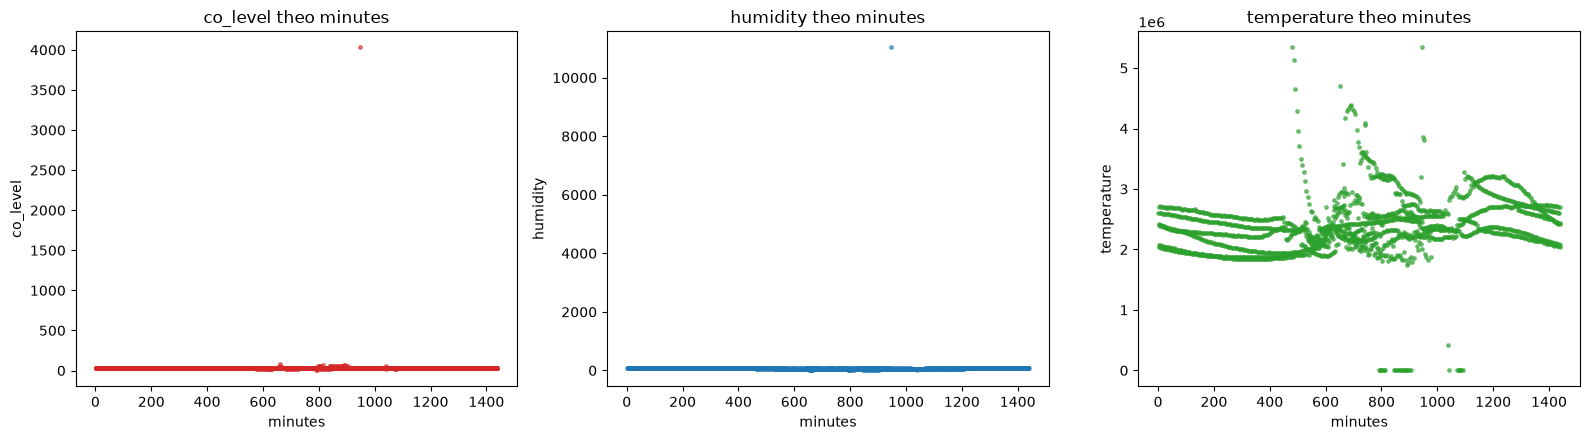

In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, color in zip(axes, ['co_level', 'humidity', 'temperature'], ['tab:red', 'tab:blue', 'tab:green']):
    ax.scatter(df['minutes'], df[col], s=6, alpha=0.6, color=color)
    ax.set_xlabel('minutes'); ax.set_ylabel(col); ax.set_title(f'{col} theo minutes')
plt.tight_layout(); plt.show()